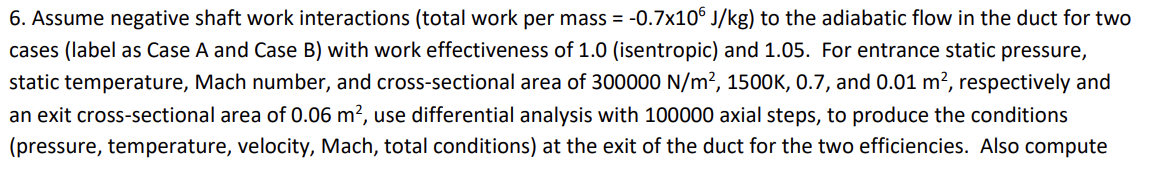

In [21]:
import numpy as np
from quasi_1D import quasi_1D_flow
import matplotlib.pyplot as plt

import scipy as sp

In [22]:
Cp = 1004.5
R = 287
gamma = 1.4

# Numerical

In [23]:
Pi = 300_000
Ti = 1500
Mi = 0.7
ui = Mi * np.sqrt(1.4*287*Ti)


w = -0.7e+6
eta = 1

L_tube = 1
axial_steps = 100_000

Ai = 0.01
Ae = 0.06

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: (Ae - Ai) * x + Ai


[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps, L = L_tube, w = w, eta= eta)

0


In [24]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')


exit Mach =             0.5462038180747403
exit Velocity =         327.8447913771453 m/s

exit Temp =             896.6380830612419 k
exit Total Temp =       950.138435093658 k

exit Pressure =         49539.60080634465 Pa
exit Total Pressure =   60680.125863807036 Pa

Thrust =                -844.1290355536939 N


# Analytical

In [25]:
Tti = Tt[0]
Pti = Pt[0]

Tte = w/Cp + Tti
Pte = Pti * (Tte/Tti)**(gamma/(gamma-1))

m_dot = lambda M: Pte/np.sqrt(R*Tte) * M*(1+(gamma-1)/2*M**2)**(1/2)/(1+(gamma-1)/2*M**2)**(gamma/(gamma-1)) * np.sqrt(gamma)* Ae
func = lambda M: m_dot(M) - Pi/(R*Ti) * ui * Ai

Me = sp.optimize.fsolve(func,.19)[0]

Te = Tte/(1+(gamma-1)/2*Me**2)
Pe = Pte/(1+(gamma-1)/2*Me**2)**(gamma/(gamma-1))
rho0 = Pi/(R*Ti)
rho = Pe / (R*Te)
ue = Me * np.sqrt(gamma*R*Te)
Thrust_a = (rho*ue**2+Pe)*Ae - (rho0*ui**2+Pi)*Ai

# Numerical

In [27]:
Pi = 300_000
Ti = 1500
Mi = 0.7
ui = Mi * np.sqrt(1.4*287*Ti)


w = -0.7e+6
eta = 1.05

L_tube = 1
axial_steps = 200_0000

Ai = 0.01
Ae = 0.06

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: (Ae - Ai) * x + Ai


[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps, L = L_tube, w = w, eta= eta)

0


In [28]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')


exit Mach =             0.6444985350509991
exit Velocity =         382.6400205928463 m/s

exit Temp =             877.2572801069347 k
exit Total Temp =       950.1360184639748 k

exit Pressure =         41530.07253450632 Pa
exit Total Pressure =   54912.155673508736 Pa

Thrust =                -1117.1366750447173 N
